Using device: cpu
Aggregating CA1 responses across 459 EIDs...


Dispatching jobs:  10%|█         | 48/459 [00:20<03:13,  2.12it/s]/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Dispatching jobs: 100%|██████████| 459/459 [05:59<00:00,  1.28it/s]


Max conditions: 2, Common conditions found: [(np.float64(-1.0),), (np.float64(1.0),)]
Total neurons collected: 7231
Input to isometric flow model shape: (7231, 20)
Starting hyperparameter grid search...

Fitting model with lambda_density=0, lambda_iso=0


Training:   0%|          | 0/500 [00:00<?, ?it/s]

  ✓ Successfully fitted and plotted

Fitting model with lambda_density=0, lambda_iso=0.05


...

  ✓ Successfully fitted and plotted

Fitting model with lambda_density=0.2, lambda_iso=0.1


Training:   0%|          | 0/500 [00:00<?, ?it/s]

  ✓ Successfully fitted and plotted

Fitting model with lambda_density=0.2, lambda_iso=0.2


Training:   0%|          | 0/500 [00:00<?, ?it/s]

  ✓ Successfully fitted and plotted


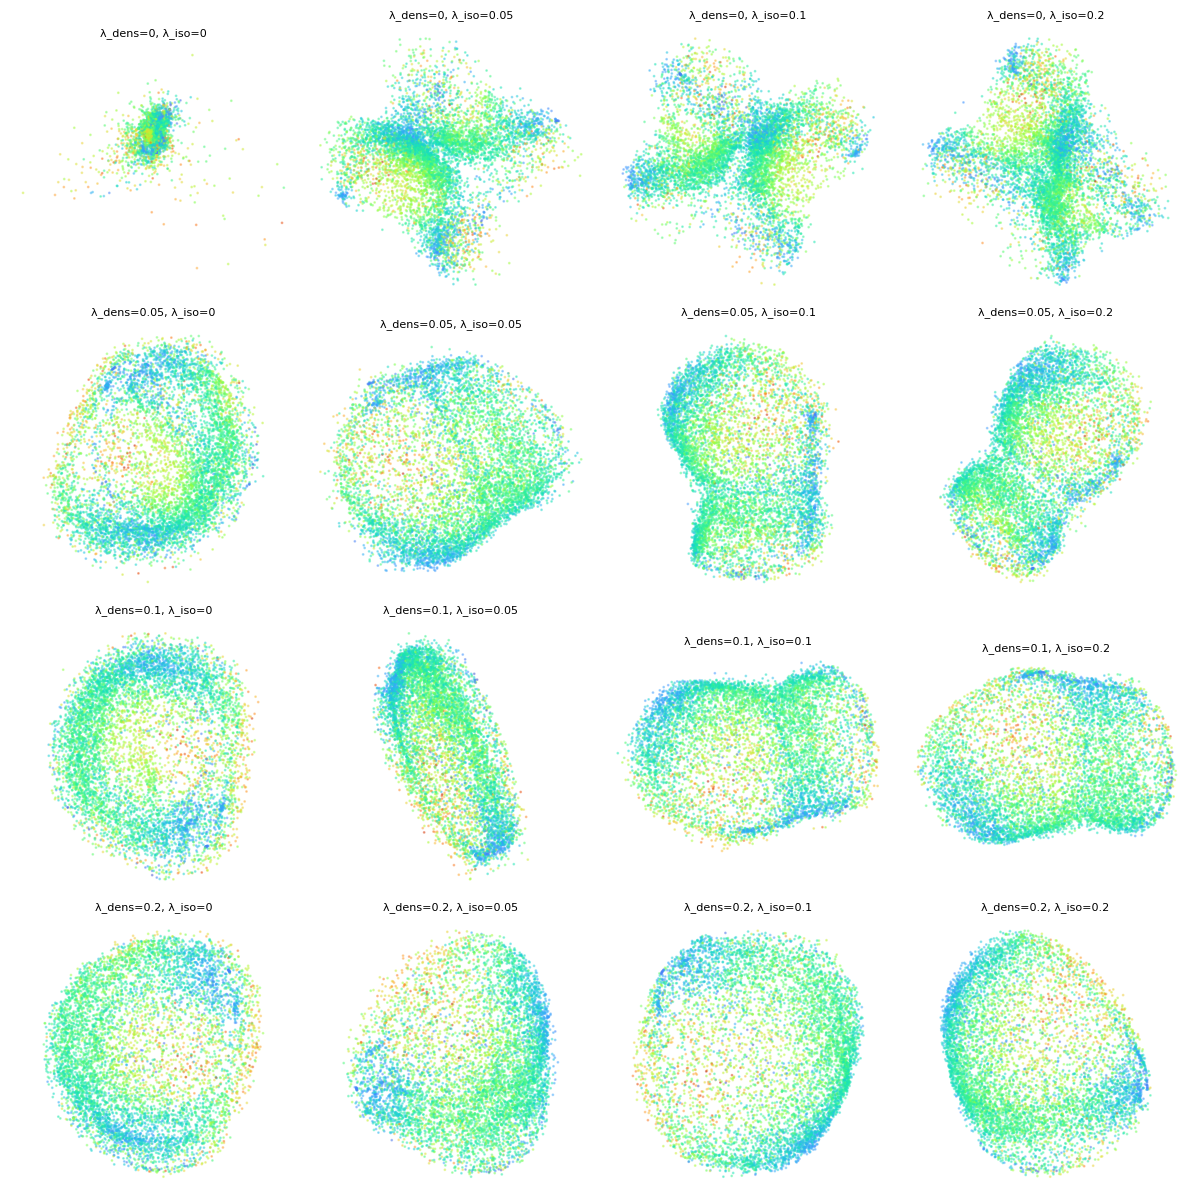


Grid search complete!

Summary of Results:
------------------------------------------------------------
λ_density=0.00, λ_iso=0.00 | Mean log prob: -0.4009
λ_density=0.00, λ_iso=0.05 | Mean log prob: -0.4009
λ_density=0.00, λ_iso=0.10 | Mean log prob: -0.4009
λ_density=0.00, λ_iso=0.20 | Mean log prob: -0.4009
λ_density=0.05, λ_iso=0.00 | Mean log prob: -0.4009
λ_density=0.05, λ_iso=0.05 | Mean log prob: -0.4009
λ_density=0.05, λ_iso=0.10 | Mean log prob: -0.4009
λ_density=0.05, λ_iso=0.20 | Mean log prob: -0.4009
λ_density=0.10, λ_iso=0.00 | Mean log prob: -0.4009
λ_density=0.10, λ_iso=0.05 | Mean log prob: -0.4009
λ_density=0.10, λ_iso=0.10 | Mean log prob: -0.4009
λ_density=0.10, λ_iso=0.20 | Mean log prob: -0.4009
λ_density=0.20, λ_iso=0.00 | Mean log prob: -0.4009
λ_density=0.20, λ_iso=0.05 | Mean log prob: -0.4009
λ_density=0.20, λ_iso=0.10 | Mean log prob: -0.4009
λ_density=0.20, λ_iso=0.20 | Mean log prob: -0.4009


In [2]:
import pandas as pd
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
import torch
import os
import sys

# Add project root to path
sys.path.append(os.path.abspath('../../'))

from BWM.bwm_functions import *
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder, get_density_proxy

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


# Set directory path and select an EID
directory_path = '../Data2'
all_items = os.listdir(directory_path)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

# Data loading using get_region_response_matrix
region = 'CA1' # Caudoputamen
response_matrix_train, condition_matrix, neuron_eids = get_region_response_matrix(
    eids=eids,
    directory_path=directory_path,
    region=region,
    mapping='Beryl',
    sigma=5,
    n_steps=100,
    threshold=5,
    min_trials_per_condition=50,
    n_pseudo=25,
    conditions=['choice'],
    event="stimOn_times",
    filter_significant=True,
    significance_threshold=0.5
)

# Average over pseudo-trials for fitting
responses = np.mean(response_matrix_train, axis=0)
# Z-score and reshape
responses_norm = (responses - np.mean(responses, axis=(0, 1), keepdims=True)) / (np.std(responses, axis=(0, 1), keepdims=True) + 1e-8)
response_matrix_flat = responses_norm.reshape(-1, responses_norm.shape[2])


def calculate_msd(responses):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    # Finite difference along time axis (axis 1)
    diff_responses = np.diff(responses, axis=1)
    # Absolute standardized derivative (already standardized in the previous cell)
    # Mean over conditions and time
    msd = np.mean(np.abs(diff_responses), axis=(0, 1))
    return msd

msd = calculate_msd(responses_norm)


# Fit Isometric Flow Model
# Transpose -> (neurons, conditions * time)
X_transposed = response_matrix_flat.T

# Scale each row (neuron) to unit length
row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
X_pre_pca = X_transposed / (row_norms + 1e-8)

# Reduce features to 20 using PCA
pca_model = PCA(n_components=20)
X_input = pca_model.fit_transform(X_pre_pca)
print(f"Input to isometric flow model shape: {X_input.shape}")

# Set plotting parameters
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameter grid
lambda_density_values = [0, 0.05, 0.1, 0.2]
lambda_iso_values = [0, 0.05, 0.1, 0.2]

# Assuming X_input and msd are already computed from previous cells
# X_input: (n_neurons, 20) - input features for the model
# msd: (n_neurons,) - mean standardized derivative values

# Create figure with subplots
n_rows = len(lambda_density_values)
n_cols = len(lambda_iso_values)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows))

# Store results for comparison
results = {}

print("Starting hyperparameter grid search...")

for i, lambda_dens in enumerate(lambda_density_values):
    for j, lambda_iso_val in enumerate(lambda_iso_values):
        
        print(f"\nFitting model with lambda_density={lambda_dens}, lambda_iso={lambda_iso_val}")
        
        # Initialize and fit autoencoder
        autoencoder = SklearnIsometricAutoencoder(
            latent_dim=2, 
            hidden_dim=64,
            depth=4, 
            epochs=500,  # Reduced for faster iteration
            batch_size=128,
            lambda_iso=lambda_iso_val, 
            lambda_density=lambda_dens,
            verbose=True,  # Set to False to reduce output
            device=device,
            lr=0.001,
            patience=100,
            r2_diff_threshold=0.2
        )
        
        try:
            autoencoder.fit(X_input)
            
            # Transform to latent space
            z_neurons = autoencoder.transform(X_input)
            log_px_latent = -get_density_proxy(X_input, k=10).numpy()
            
            # Store results
            results[(lambda_dens, lambda_iso_val)] = {
                'z_neurons': z_neurons,
                'log_px_latent': log_px_latent,
                'autoencoder': autoencoder
            }
            
            # Plot: Colored by MSD (second subplot style)
            ax = axes[i, j] if n_rows > 1 and n_cols > 1 else axes
            
            vmin_msd, vmax_msd = np.percentile(msd, [0, 100])
            range_msd = vmax_msd - vmin_msd
            vmin_msd -= 0.1 * range_msd
            vmax_msd += 0.1 * range_msd
            
            ax.scatter(z_neurons[:, 0], z_neurons[:, 1], 
                      c=msd, cmap='turbo', s=1, alpha=0.4, 
                      vmin=vmin_msd, vmax=vmax_msd)
            
            ax.set_title(f'λ_dens={lambda_dens}, λ_iso={lambda_iso_val}', fontsize=8)
            ax.set_aspect('equal')
            ax.axis('off')
            
            print(f"  ✓ Successfully fitted and plotted")
            
        except Exception as e:
            print(f"  ✗ Error: {e}")
            ax = axes[i, j] if n_rows > 1 and n_cols > 1 else axes
            ax.text(0.5, 0.5, 'Failed', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f'λ_dens={lambda_dens}, λ_iso={lambda_iso_val}', fontsize=8)
            ax.axis('off')

plt.tight_layout()
plt.savefig("../Figures/HyperparameterGrid_IsometricFlow.png", 
            bbox_inches='tight', dpi=300, transparent=True)
plt.show()

print("\n" + "="*60)
print("Grid search complete!")
print("="*60)

# Optional: Print summary statistics for each configuration
print("\nSummary of Results:")
print("-" * 60)
for (ld, li), res in results.items():
    if 'log_px_latent' in res:
        mean_logp = np.mean(res['log_px_latent'])
        print(f"λ_density={ld:4.2f}, λ_iso={li:4.2f} | Mean log prob: {mean_logp:7.4f}")
